<div style="background:#14243A;color:#FFFFFF;padding:28px 30px;border-radius:14px;margin-bottom:14px;">
<div style="font-size:12px;letter-spacing:2px;color:#A9C9F4;font-weight:700;">NLP · TRANSFORMERS · GENERATIVE AI</div>
<h1 style="color:#FFFFFF;margin:10px 0 8px 0;font-size:32px;">Steam Game Description Generator</h1>
<p style="font-size:17px;color:#DBE7F7;margin:0;">Fine-tuning GPT-2 to generate game descriptions from genre prompts</p>
<div style="font-size:13px;color:#A9C9F4;margin-top:16px;">Version 1 · Project walkthrough and demonstration</div>
</div>

**Research question:** Can a pretrained language model learn to write descriptions that reflect a game's genres?

**Main takeaway:** After two fine-tuning epochs, training and validation loss both declined. The model generated genre-related descriptions for RPG, horror, and farming prompts, although grammar and coherence remain inconsistent.

> **Presentation guide:** This notebook contains recorded results so you can present without rerunning training. For a live demo, use the interactive cell near the end. Re-running training cells will continue updating weights; restart and run sequentially only when deliberately retraining.

## Project snapshot

| Item | Version 1 |
|:--|:--|
| **Task** | Genre-conditioned game-description generation |
| **Model** | Pretrained GPT-2 (`openai-community/gpt2`) |
| **Data source** | Kaggle — *Steam Games Reviews and Rankings* (using `games_description.csv`) |
| **Examples** | 290 games: **232 training / 58 validation** |
| **Sequence length** | Maximum 1,024 GPT-2 tokens |
| **Fine-tuning** | 2 epochs · AdamW · learning rate `2e-5` · batch size 4 |
| **Best observed validation loss** | **3.5802** (Epoch 2) |

### Presentation route
**Problem → Data → Preprocessing → Model pipeline → Training → Results → Demo → Limitations.**

*Method note:* The source dataset contains other files, but Version 1 trains on game **genres** and **long descriptions** only; reviews and ranking data are not used in the model.

---
## 1. Research problem and approach

Steam descriptions vary in tone, detail, and content. This project asks whether a pretrained text model can learn a simple relationship:

**Input:** `Genres: Action RPG, Mythology, Adventure`  
**Target:** A plausible game description associated with those genres.

We **fine-tune** GPT-2 rather than training a Transformer from scratch. We provide genres as a prompt and teach the model to predict the description text that follows. This is a *working baseline*, not a production-quality generator.

## 2. Data acquisition and exploration

**Source:** Kaggle `mohamedtarek01234/steam-games-reviews-and-rankings`.

For this baseline, we use `games_description.csv`. The file has **290 games** with genre metadata and long descriptions. The other dataset files are not necessary for this notebook's training pipeline.

**Run requirements:** Google Colab with a GPU recommended; packages include `kagglehub`, `pandas`, `torch`, `scikit-learn`, `transformers`, `tiktoken`, and `matplotlib`. Install missing packages before running from a clean runtime:

```python
%pip install -q kagglehub pandas numpy torch scikit-learn transformers tiktoken matplotlib
```

*When presenting, you can skip execution and discuss the saved outputs below.*

In [1]:
import random as rand
import numpy as np
import torch

SEED_num = 42
rand.seed(SEED_num)
torch.manual_seed(SEED_num)

if torch.cuda.is_available():
  torch.cuda.manual_seed_all(SEED_num)

print(f"Random seed: {SEED_num}")

Random seed: 42


In [2]:
import kagglehub

dataset_path = kagglehub.dataset_download(
    "mohamedtarek01234/steam-games-reviews-and-rankings"
)

print("Dataset location: ", dataset_path)

Using Colab cache for faster access to the 'steam-games-reviews-and-rankings' dataset.
Dataset location:  /kaggle/input/steam-games-reviews-and-rankings


In [3]:
import pandas as pd
from pathlib import Path

dataset_path = Path(dataset_path)
descriptions_df = pd.read_csv(dataset_path / "games_description.csv")
print("Game descriptions shape:", descriptions_df.shape)
print("Columns:", descriptions_df.columns.tolist())

Game descriptions shape: (290, 13)
Columns: ['name', 'short_description', 'long_description', 'genres', 'minimum_system_requirement', 'recommend_system_requirement', 'release_date', 'developer', 'publisher', 'overall_player_rating', 'number_of_reviews_from_purchased_people', 'number_of_english_reviews', 'link']


**Recorded inspection:** `games_description.csv` contains **290 rows and 13 columns**. For this project the important fields are `name`, `genres`, `long_description`, and (for comparison) `short_description`.

In [4]:
# Checking to see either we should use long_description or short_description based on average
average_long = descriptions_df["long_description"].str.split().str.len().mean()
average_short = descriptions_df['short_description'].str.split().str.len().mean()

print(f"Average for long_description: {average_long}")
print(f"Average for short_description: {average_short}")


Average for long_description: 324.12068965517244
Average for short_description: 35.68953068592058


**Why long descriptions?** The original descriptions average approximately **324 words**, compared with **36 words** for short descriptions. We selected the longer field to provide richer training targets. This choice also creates more long sequences, increasing training memory usage.

## 3. Cleaning and checking the training data

The training table keeps just three source columns. Before training, we check for missing values, duplicate games, and empty descriptions. Text cleaning normalizes spacing around punctuation, bullet points, and whitespace. We retain the original game text content rather than rewriting it.

In [5]:
# Create our training DataFrame
training_df = descriptions_df[
    ["name", "genres", "long_description"]
].copy()

In [6]:
# Checking for missing data
print(training_df.isnull().sum())
print("Duplicate games:", training_df["name"].duplicated().sum())

name                0
genres              0
long_description    0
dtype: int64
Duplicate games: 0


In [7]:
# Checking for duplicate games
print("Duplicate games:", training_df["name"].duplicated().sum())

print("Duplicate descriptions:",
      training_df["long_description"].duplicated().sum())

Duplicate games: 0
Duplicate descriptions: 0


In [8]:
# Checking for empty descriptions
print("Empty descriptions:",
      (training_df["long_description"].str.strip() == "").sum())

Empty descriptions: 0


In [9]:
# Cleaning the text


import re

def clean_description(text):
    # Add space after punctuation when followed by a letter
    text = re.sub(r'([.!?])([A-Za-z])', r'\1 \2', text)

    # Add space after commas when followed by a letter
    text = re.sub(r'([,;:])([A-Za-z])', r'\1 \2', text)

    # Add space before bullet points
    text = re.sub(r'([^\s])•', r'\1 •', text)

    # Remove extra whitespace
    text = re.sub(r'\s+', ' ', text)

    # Add space after a closing quote that follows sentence punctuation
    text = re.sub(r'([.!?]")([A-Za-z])', r'\1 \2', text)

    # Add space before an opening quotation mark
    text = re.sub(r'([A-Za-z])(")', r'\1 \2', text)

    return text.strip()



In [10]:
training_df["clean_description"] = (
    training_df["long_description"].apply(clean_description)
)

In [11]:
training_df[
    ["name", "genres", "clean_description"]
].head()

,name,genres,clean_description
0,Black Myth: Wukong,"['Mythology', 'Action RPG', 'Action', 'RPG', '...",About This Game Black Myth: Wukong is an actio...
1,Counter-Strike 2,"['FPS', 'Shooter', 'Multiplayer', 'Competitive...","About This Game For over two decades, Counter-..."
2,"Warhammer 40,000: Space Marine 2","['Warhammer 40K', 'Action', 'Third-Person Shoo...",About This Game Embody the superhuman skill an...
3,Cyberpunk 2077,"['Cyberpunk', 'Open World', 'Nudity', 'RPG', '...",About This Game Cyberpunk 2077 is an open-worl...
4,ELDEN RING,"['Souls-like', 'Dark Fantasy', 'Open World', '...",About This Game THE CRITICALLY ACCLAIMED FANTA...


In [12]:
word_counts = training_df["clean_description"].str.split().str.len()

print("Average words:", word_counts.mean())
print("Minimum words:", word_counts.min())
print("Maximum words:", word_counts.max())

Average words: 330.28620689655173
Minimum words: 3
Maximum words: 1404


**Data-quality result:** The selected fields have no missing values, and the notebook found no duplicate game names, duplicate long descriptions, or empty long descriptions. After whitespace cleanup, descriptions average approximately **330 words**.

## 4. Tokenization and training targets

GPT-2 reads **token IDs**, not raw strings. We use `tiktoken` with GPT-2 encoding and format each example as:

```text
Genres: ['Action RPG', 'Mythology', 'Adventure']
Description: [actual game description] <|endoftext|>
```

The actual `genres` field contains the genre string from the dataset. The example above illustrates the structure, not a specific training row.

We **mask prompt positions with `-100`** so that the language-modeling loss is calculated on the description and end-of-text token, not on the genre prompt. Descriptions exceeding the remaining 1,024-token budget are truncated.

In [13]:
import tiktoken

enc = tiktoken.get_encoding("gpt2")

In [14]:
training_df["token_count"] = training_df["clean_description"].apply(
    lambda text: len(enc.encode(text))
)

In [15]:
print("Average tokens:", training_df["token_count"].mean())
print("Maximum tokens:", training_df["token_count"].max())

print("Descriptions over 512 tokens:",
      (training_df["token_count"] > 512).sum())

print("Descriptions over 1024 tokens:",
      (training_df["token_count"] > 1024).sum())

Average tokens: 430.2758620689655
Maximum tokens: 2907
Descriptions over 512 tokens: 88
Descriptions over 1024 tokens: 8


In [16]:
eos_token = enc.eot_token

print("End-of-text token ID:", eos_token)

End-of-text token ID: 50256


In [17]:
def tokenize_example(genres, description, max_length=1024):
    prompt = f"Genres: {genres}\nDescription:"
    prompt_tokens = enc.encode(prompt)
    description_tokens = enc.encode(" " + description)

    available_space = max_length - len(prompt_tokens) - 1  # reserve EOS
    if available_space < 1:
        raise ValueError("Genre prompt is too long for max_length")
    description_tokens = description_tokens[:available_space]

    input_ids = prompt_tokens + description_tokens + [eos_token]
    labels = [-100] * len(prompt_tokens) + description_tokens + [eos_token]
    return {"input_ids": input_ids, "labels": labels}

In [18]:
# Running this example with the updated tokenizer function

result = tokenize_example(
    training_df["genres"].iloc[0],
    training_df["clean_description"].iloc[0]
)

print("Input length:", len(result["input_ids"]))
print("Labels length:", len(result["labels"]))
print("First 10 labels:", result["labels"][:10])
print("Last label:", result["labels"][-1])

Input length: 514
Labels length: 514
First 10 labels: [-100, -100, -100, -100, -100, -100, -100, -100, -100, -100]
Last label: 50256


**Token-length observation:** Average description length is approximately **430 tokens**; the longest is **2,907 tokens**. **8 descriptions exceed 1,024 tokens**, so truncation is necessary for the current GPT-2 context window (and genre prompts also take up some of that window).

**Training design:** GPT-2 receives genre text as context; only description tokens contribute to the loss.

## 5. PyTorch dataset and batching

The custom `SteamDataset` produces `input_ids` and `labels` for one game at a time. The `collate_fn` pads examples so multiple games can be batched:

| Tensor | Padding value | Reason |
|--|--:|--|
| `input_ids` | `50256` (EOS) | Fill unused input positions |
| `labels` | `-100` | Ignore padding during loss calculation |
| `attention_mask` | `0` | Mark padding as not real input |

An **80/20 train-validation split** gives **232 training** and **58 validation** games, with batch size **4**.

In [19]:
# Import the dataset
from torch.utils.data import Dataset

# Create a Dataset class
class SteamDataset(Dataset):
  def __init__(self, dataframe):
    self.dataframe = dataframe

  def __len__(self):
    return len(self.dataframe)

  def __getitem__(self, idx):
    row = self.dataframe.iloc[idx]

    tokens = tokenize_example(
        row["genres"],
        row["clean_description"]
    )

    return tokens

In [20]:


import torch
from torch.nn.utils.rnn import pad_sequence

def collate_fn(batch):
    # Convert token lists into PyTorch tensors
    input_ids = [
        torch.tensor(item["input_ids"], dtype=torch.long)
        for item in batch
    ]

    labels = [
        torch.tensor(item["labels"], dtype=torch.long)
        for item in batch
    ]

    # Create attention masks before padding
    attention_masks = [
        torch.ones_like(ids)
        for ids in input_ids
    ]

    # Pad input IDs
    padded_inputs = pad_sequence(
        input_ids,
        batch_first=True,
        padding_value=eos_token
    )

    # Pad labels
    padded_labels = pad_sequence(
        labels,
        batch_first=True,
        padding_value=-100
    )

    # Pad attention masks
    padded_masks = pad_sequence(
        attention_masks,
        batch_first=True,
        padding_value=0
    )

    # Return the batch
    return {
        "input_ids": padded_inputs,
        "labels": padded_labels,
        "attention_mask": padded_masks
    }




In [21]:
from sklearn.model_selection import train_test_split


train_df, val_df = train_test_split(
    training_df,
    test_size=0.2,
    random_state=SEED_num,
    shuffle=True
)

print("Training games:", len(train_df))
print("Validation games:", len(val_df))

Training games: 232
Validation games: 58


In [22]:

train_dataset = SteamDataset(train_df)
val_dataset = SteamDataset(val_df)

print("Training examples:", len(train_dataset))
print("Validation examples:", len(val_dataset))


Training examples: 232
Validation examples: 58


In [23]:
from torch.utils.data import DataLoader


train_loader = DataLoader(
    train_dataset,
    batch_size=4,
    shuffle=True,
    collate_fn=collate_fn
)

val_loader = DataLoader(
    val_dataset,
    batch_size=4,
    shuffle = False,
    collate_fn = collate_fn
)


In [24]:
batch = next(iter(train_loader))

print("Input shape:", batch["input_ids"].shape)
print("Labels shape:", batch["labels"].shape)
print("Attention mask shape:", batch["attention_mask"].shape)

print("Training batches:", len(train_loader))
print("Validation batches:", len(val_loader))

Input shape: torch.Size([4, 1024])
Labels shape: torch.Size([4, 1024])
Attention mask shape: torch.Size([4, 1024])
Training batches: 58
Validation batches: 15


**Batch verification:** The recorded batch shapes were **`[4, 1024]`** for inputs, labels, and attention masks, with **58 training batches** and **15 validation batches**. Padding ensures shapes agree even when descriptions have different lengths.

## 6. Pretrained model and fine-tuning

We load **GPT-2 (124M-parameter class)** and fine-tune it with **AdamW** at learning rate **`2e-5`**. Each training batch follows:

`zero gradients → forward pass → calculate loss → backward pass → optimizer step`

During validation, the model switches to evaluation mode and uses `torch.no_grad()`; **no weights are updated**.

> **Reproduction caution:** The next cells train GPT-2. For a presentation, show the recorded results rather than rerunning unless you have a GPU and intend to train again.

In [25]:
from transformers import GPT2LMHeadModel


model_name = "openai-community/gpt2"

model = GPT2LMHeadModel.from_pretrained(model_name)

model.config.pad_token_id = eos_token

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

model = model.to(device)

print("Using device:", device)

config.json:   0%|          | 0.00/665 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  548MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/148 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/124 [00:00<?, ?B/s]

Using device: cuda


In [26]:
from torch.optim import AdamW

learning_rate = 2e-5

optimizer = AdamW(
    model.parameters(),
    lr=learning_rate
)

### Epoch 1 — Train and validate

In [27]:
# Train GPT-2 for one epoch

model.train()

# Track the total training loss
total_loss = 0

# Loop through all training batches
for batch in train_loader:

    # Step 1: Clear previous gradients
    optimizer.zero_grad()

    # Step 2: Move tensors to GPU or CPU
    input_ids = batch["input_ids"].to(device)
    labels = batch["labels"].to(device)
    attention_mask = batch["attention_mask"].to(device)

    # Step 3: Forward pass
    outputs = model(
        input_ids=input_ids,
        attention_mask=attention_mask,
        labels=labels
    )

    # Step 4: Calculate loss
    loss = outputs.loss

    # Step 5: Backpropagation
    loss.backward()

    # Step 6: Update model weights
    optimizer.step()

    # Step 7: Track training loss
    total_loss += loss.item()

# Step 8: Calculate average loss
average_loss = total_loss / len(train_loader)

print("Average training loss:", average_loss)


[transformers] `loss_type=None` was set in the config but it is unrecognized. Using the default loss: `ForCausalLMLoss`.


Average training loss: 3.7026375737683526


In [28]:

# Set GPT-2 to evaluation mode
model.eval()

total_val_loss = 0

# Disable gradient calculations
with torch.no_grad():
    for batch in val_loader:
        input_ids = batch["input_ids"].to(device)
        labels = batch["labels"].to(device)
        attention_mask = batch["attention_mask"].to(device)

        # Forward pass
        outputs = model(
            input_ids=input_ids,
            attention_mask=attention_mask,
            labels=labels
        )

        # Track validation loss
        loss = outputs.loss
        total_val_loss += loss.item()

# Calculate average validation loss
average_val_loss = total_val_loss / len(val_loader)

print("Average training loss:", average_loss)
print("Average validation loss:", average_val_loss)


Average training loss: 3.7026375737683526
Average validation loss: 3.597188933690389


### Epoch 2 — Continue fine-tuning and validate

In [29]:

# Epoch 2: Training
model.train()
total_loss = 0

for batch in train_loader:
    optimizer.zero_grad()

    input_ids = batch["input_ids"].to(device)
    labels = batch["labels"].to(device)
    attention_mask = batch["attention_mask"].to(device)

    outputs = model(
        input_ids=input_ids,
        attention_mask=attention_mask,
        labels=labels
    )

    loss = outputs.loss
    loss.backward()
    optimizer.step()

    total_loss += loss.item()

average_loss = total_loss / len(train_loader)

print("Epoch 2 training loss:", average_loss)


Epoch 2 training loss: 3.5264018280752776


In [30]:

# Epoch 2: Validation

# Step 1: Set the model to evaluation mode
model.eval()

# Step 2: Reset validation loss
total_val_loss = 0

# Step 3: Disable gradient calculations
with torch.no_grad():

    # Step 4: Loop through validation batches
    for batch in val_loader:

        # Move tensors to GPU or CPU
        input_ids = batch["input_ids"].to(device)
        labels = batch["labels"].to(device)
        attention_mask = batch["attention_mask"].to(device)

        # Forward pass
        outputs = model(
            input_ids=input_ids,
            attention_mask=attention_mask,
            labels=labels
        )

        # Calculate validation loss
        loss = outputs.loss

        # Accumulate validation loss
        total_val_loss += loss.item()

# Step 5: Calculate average validation loss
average_val_loss = total_val_loss / len(val_loader)

# Step 6: Display Epoch 2 results
print("Epoch 2 training loss:", average_loss)
print("Epoch 2 validation loss:", average_val_loss)


Epoch 2 training loss: 3.5264018280752776
Epoch 2 validation loss: 3.580172634124756


## 7. Results — Did training help?

| Metric | Epoch 1 | Epoch 2 | Direction |
|:--|--:|--:|:--|
| **Training loss** | 3.7026 | **3.5264** | ↓ 4.76% |
| **Validation loss** | 3.5972 | **3.5802** | ↓ 0.47% |

Both metrics improved. Validation improved only slightly, so **two epochs do not establish strong generalization**. The results support a useful baseline, not a claim that descriptions are consistently high quality.

**Talk track:** “The training loss fell more than the validation loss. I therefore evaluated generated examples instead of assuming that lower training loss meant better writing.”

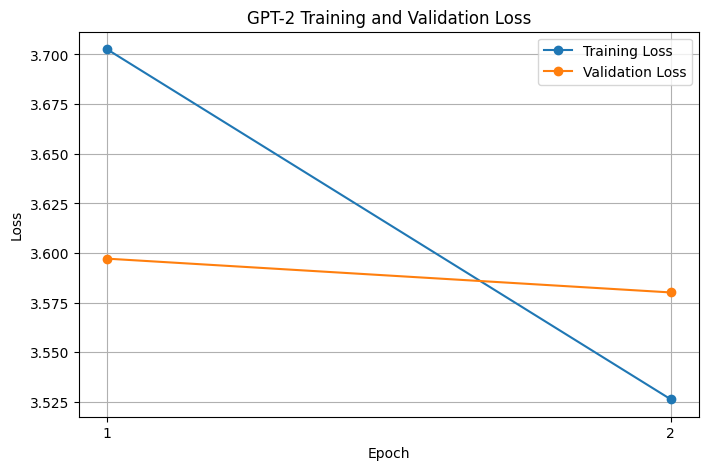

In [31]:

import matplotlib.pyplot as plt

# Training results from Epoch 1 and Epoch 2
epochs = [1, 2]

training_losses = [
    3.702637532661701,
    3.52640190206725
]

validation_losses = [
    3.5971890926361083,
    3.580172650019328
]

# Create the line graph
plt.figure(figsize=(8, 5))

plt.plot(
    epochs,
    training_losses,
    marker="o",
    label="Training Loss"
)

plt.plot(
    epochs,
    validation_losses,
    marker="o",
    label="Validation Loss"
)

plt.title("GPT-2 Training and Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.xticks(epochs)
plt.legend()
plt.grid(True)

plt.show()


## 8. Qualitative results — Does the genre prompt matter?

Three genre prompts were tested using sampling (`temperature=0.7`, `top_p=0.9`) with repetition controls. These are **observed examples from the original notebook**, not hand-written descriptions.

**Action RPG · Mythology · Adventure** — The model discussed fantasy settings, exploration, and combat, but also mixed established game franchises and settings. This demonstrates genre-related vocabulary **and** problems with originality and coherence.

**Horror · Survival · Psychological** — It started: “About This Game Explore an abandoned village with no sign of life.” This has a horror tone, but later sentences become implausible and grammatically awkward.

**Simulation · Farming · Casual** — It started: “About This Game You play the role of a farmer in an attempt to survive and thrive. But you can't just farm!” It introduced crops, harvesting, and resources, but drifted toward survival themes and confusing sentences.

**Interpretation:** The samples differ in subject matter in ways consistent with the prompts. However, because sampling is random and the test set is small, this is **suggestive**, not proof of reliable genre control.

## 9. Live demonstration — Enter genres

Use the following helper to generate a description for **any genre string** without changing the training code. It uses the same prompt format, tokenizer, and generation configuration tested above. It removes GPT-2's end-of-text marker from display.

**For a presentation:** If your Colab session has reset, restore the model from a previously saved model folder before running this demo. The `.ipynb` file does **not** contain trained weights.

In [32]:
def generate_description(genres, max_new_tokens=200):
    model.eval()
    prompt = f"Genres: {genres}\nDescription:"
    inputs = torch.tensor([enc.encode(prompt)], dtype=torch.long).to(device)

    with torch.no_grad():
        generated = model.generate(
            input_ids=inputs,
            max_new_tokens=max_new_tokens,
            do_sample=True,
            temperature=0.7,
            top_p=0.9,
            repetition_penalty=1.1,
            no_repeat_ngram_size=3,
            pad_token_id=eos_token,
            eos_token_id=eos_token,
        )

    new_tokens = generated[0, inputs.shape[1]:].tolist()
    if eos_token in new_tokens:
        new_tokens = new_tokens[:new_tokens.index(eos_token)]
    return enc.decode(new_tokens).strip()

# Change this string to demo another genre combination.
demo_genres = "Simulation, Farming, Casual"
print("Genres:", demo_genres)
print("Generated description:", generate_description(demo_genres))

Genres: Simulation, Farming, Casual
Generated description: About This Game The classic Farm Simulator features the first ever multiplayer farm game for Windows PC. With more than 200 hours of gameplay and over 100 unique events to play through each season - get your hands on an authentic experience in a virtual world you can enjoy! No one knows when they will come back from vacation or just see their family again but it's never too early to start building up memories with all those unforgettable moments together...


## 10. Save Version 1

Save the trained weights and a small metadata file describing how prompts were formatted. **Save to Google Drive or download the folder before Colab resets**, because files under `/content/` are temporary. You can also reload the model later with `GPT2LMHeadModel.from_pretrained(save_path)`.

The recorded save result in the original notebook was `/content/steam_gpt2_v1`. This presentation notebook does **not** bundle the 500MB+ model weights.

In [33]:

# Save the fine-tuned GPT-2 model
save_path = "/content/steam_gpt2_v1"

model.save_pretrained(save_path)

print("Model saved to:", save_path)


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Model saved to: /content/steam_gpt2_v1


In [34]:

import json
import os

config = {
    "encoding": "gpt2",
    "prompt_format": "Genres: {genres}\nDescription:",
    "eos_token_id": eos_token,
    "max_length": 1024
}

with open(os.path.join(save_path, "generation_config_info.json"), "w") as f:
    json.dump(config, f, indent=4)


## 11. Limitations, next steps, and conclusion

### Limitations
- **Small dataset:** Only 232 training examples; generated text is often grammatical in places but inconsistent overall.
- **Genre fidelity is imperfect:** The model sometimes drifts from the requested genre or mixes unrelated mechanics.
- **Existing franchise names:** Generated descriptions can include recognizable intellectual property rather than original worlds.
- **Long-text truncation:** A 1,024-token context limit clips some descriptions.
- **Limited evaluation:** Two epochs and three qualitative prompts do not quantify creativity, originality, or long-form coherence.

### Possible Version 2 improvements
- Increase the number and diversity of well-cleaned game descriptions.
- Use a consistent prompt/output template with gameplay details and genre tags.
- Evaluate multiple generations per genre using a simple human-rating rubric.
- Compare more training checkpoints and stop when validation stops improving.

### Conclusion
**Version 1 demonstrates an end-to-end GPT-2 fine-tuning workflow** — from Steam data preparation to genre-conditioned text generation. The model produces genre-related descriptions and shows modest validation improvement, while also exposing the limits of fine-tuning a language model on a small dataset.

**Closing line for the presentation:** “This project established a working baseline. My next priority would be improving data quality and evaluating genre consistency rather than treating lower training loss as the only measure of success.”